In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_excel("/Sales_Analysis_Dataset.xlsx")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1200, 13)


,Order_ID,Order_Date,Customer_Name,Category,Sub_Category,Product_Name,Region,State,Sales,Quantity,Discount,Profit,Payment_Mode
0,ORD10001,2024-02-02,Aarav Sharma,Office Supplies,Paper,Premium Paper,North,Haryana,9332.0,4,0.00,1848.66,UPI
1,ORD10002,2024-06-12,Rohan Khan,Technology,Smartphones,Basic Smartphones,North,Punjab,109522.0,7,0.00,25382.98,Debit Card
2,ORD10003,2024-02-14,Neha Yadav,Furniture,Desks,Premium Desks,South,Telangana,7144.2,2,0.10,1255.56,Net Banking
3,ORD10004,2024-10-23,Priya Singh,Technology,Keyboards,Basic Keyboards,North,Haryana,234222.0,6,0.00,49714.24,Credit Card
4,ORD10005,2025-12-19,Priya Singh,Technology,Keyboards,Basic Keyboards,East,Jharkhand,67596.3,6,0.05,13623.02,Net Banking


In [8]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (1200, 13)

Column Names:
['Order_ID', 'Order_Date', 'Customer_Name', 'Category', 'Sub_Category', 'Product_Name', 'Region', 'State', 'Sales', 'Quantity', 'Discount', 'Profit', 'Payment_Mode']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       1200 non-null   object        
 1   Order_Date     1200 non-null   datetime64[ns]
 2   Customer_Name  1200 non-null   object        
 3   Category       1200 non-null   object        
 4   Sub_Category   1200 non-null   object        
 5   Product_Name   1200 non-null   object        
 6   Region         1200 non-null   object        
 7   State          1200 non-null   object        
 8   Sales          1200 non-null   float64       
 9   Quantity       1200 non-null   int64         
 10  Discount       1200 non-null   float64       
 

In [9]:
# Statistical Summary
print("Statistical Summary:")
display(df.describe())

# Total Sales
print("Total Sales:", df["Sales"].sum())

# Total Profit
print("Total Profit:", df["Profit"].sum())

# Total Quantity
print("Total Quantity:", df["Quantity"].sum())

# Average Discount
print("Average Discount:", df["Discount"].mean())

# Overall Profit Margin
profit_margin = (df["Profit"].sum() / df["Sales"].sum()) * 100
print("Overall Profit Margin:", round(profit_margin, 2), "%")

Statistical Summary:


,Order_Date,Sales,Quantity,Discount,Profit
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2025-01-04 15:25:12,59503.516458,4.566667,0.103000,8929.364492
min,2024-01-01 00:00:00,193.600000,1.000000,0.000000,14.530000
25%,2024-07-09 18:00:00,5834.775000,3.000000,0.050000,795.357500
50%,2025-01-08 00:00:00,23593.625000,5.000000,0.100000,2933.845000
75%,2025-07-08 00:00:00,75450.187500,7.000000,0.150000,10061.937500
max,2025-12-30 00:00:00,465062.400000,8.000000,0.200000,102339.980000
std,NaN,85989.257636,2.329537,0.069606,14366.281506


Total Sales: 71404219.75
Total Profit: 10715237.39
Total Quantity: 5480
Average Discount: 0.10300000000000001
Overall Profit Margin: 15.01 %


In [10]:
# Regional Sales Analysis

regional_sales = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "count")
    )
    .sort_values(by="Total_Sales", ascending=False)
)

display(regional_sales)

,Total_Sales,Total_Profit,Total_Orders
Region,,,
North,21731759.85,2975602.90,328
East,18091897.10,2717071.47,286
South,17129143.00,2844470.45,300
West,14451419.80,2178092.57,286


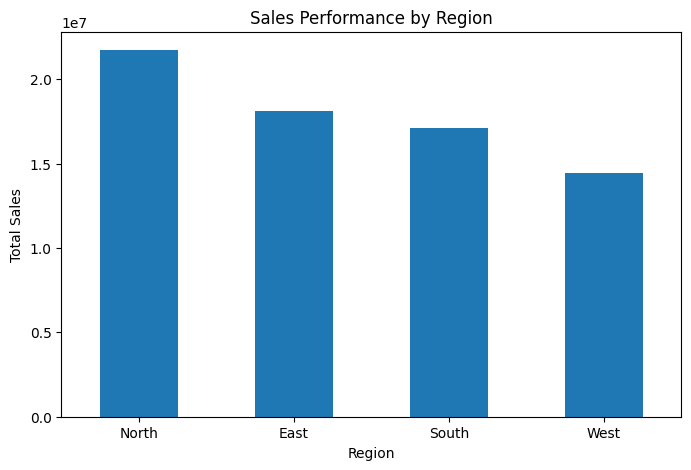

In [11]:
regional_sales["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Sales Performance by Region",
    xlabel="Region",
    ylabel="Total Sales"
)

plt.xticks(rotation=0)
plt.show()

In [12]:
# Product Sub-Category Analysis

subcategory_sales = (
    df.groupby("Sub_Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values(by="Total_Sales", ascending=False)
)

display(subcategory_sales)

,Total_Sales,Total_Profit,Total_Quantity
Sub_Category,,,
Smartphones,12449610.15,1879365.81,429
Printers,11049956.30,1640367.88,369
Keyboards,10611408.85,1615578.38,380
Monitors,9918178.65,1448882.53,346
Laptops,9367356.45,1418921.19,301
Bookcases,3460601.80,495358.63,366
Chairs,3350178.85,455224.05,430
Cabinets,3211672.85,546320.62,345
Desks,3013024.20,457673.54,426


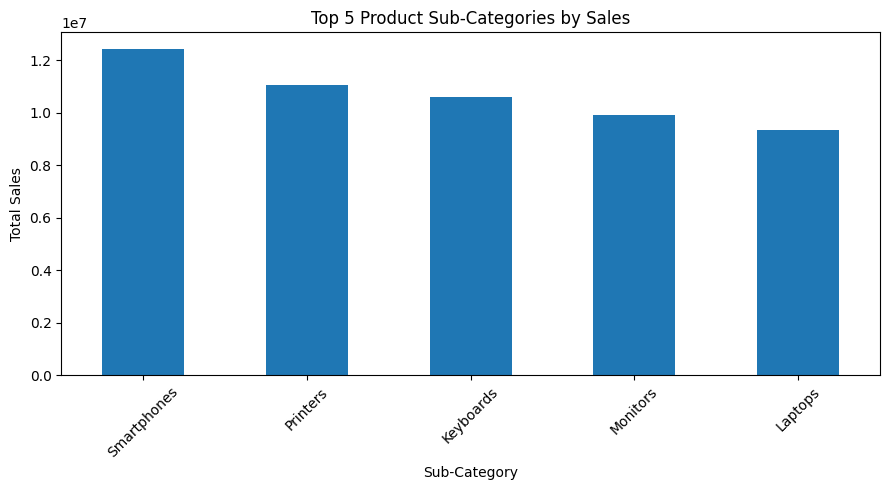

In [13]:
top_5 = subcategory_sales.head(5)

top_5["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Top 5 Product Sub-Categories by Sales",
    xlabel="Sub-Category",
    ylabel="Total Sales"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month

print("Date conversion completed!")

Date conversion completed!


In [15]:
monthly_sales = (
    df.groupby(["Year", "Month"])["Sales"]
    .sum()
    .reset_index()
)

monthly_sales["Month_Name"] = pd.to_datetime(
    monthly_sales["Month"], format="%m"
).dt.strftime("%b")

monthly_sales["Month_Year"] = (
    monthly_sales["Month_Name"] + " " +
    monthly_sales["Year"].astype(str)
)

display(monthly_sales)

,Year,Month,Sales,Month_Name,Month_Year
0,2024,1,3667694.95,Jan,Jan 2024
1,2024,2,2510187.65,Feb,Feb 2024
2,2024,3,2419223.05,Mar,Mar 2024
3,2024,4,2759890.20,Apr,Apr 2024
4,2024,5,1864093.65,May,May 2024
5,2024,6,2465048.10,Jun,Jun 2024
6,2024,7,2479254.95,Jul,Jul 2024
7,2024,8,4040262.10,Aug,Aug 2024
8,2024,9,2438921.20,Sep,Sep 2024
9,2024,10,4240651.20,Oct,Oct 2024


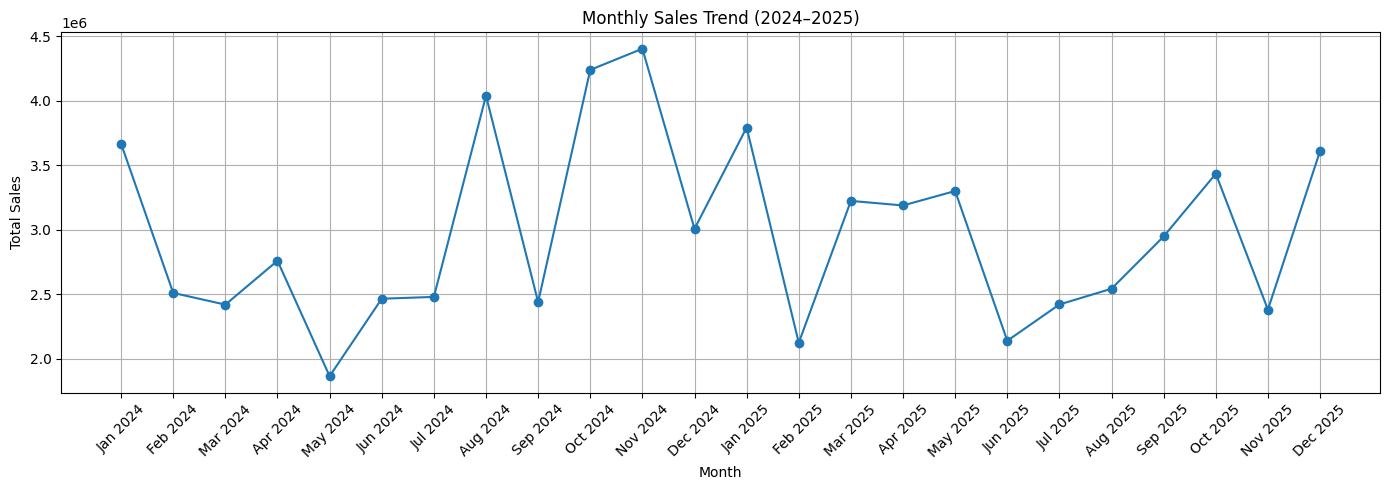

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales["Month_Year"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
from scipy.stats import ttest_ind

# Calculate order-level profit margin
df["Profit_Margin"] = df["Profit"] / df["Sales"]

# Divide orders into two groups
low_discount = df[df["Discount"] <= 0.05]["Profit_Margin"]
high_discount = df[df["Discount"] >= 0.10]["Profit_Margin"]

# Welch's independent samples t-test
t_stat, p_value = ttest_ind(
    high_discount,
    low_discount,
    equal_var=False
)

print("Low Discount Average Margin:",
      round(low_discount.mean() * 100, 2), "%")

print("High Discount Average Margin:",
      round(high_discount.mean() * 100, 2), "%")

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis (H0)")
else:
    print("Fail to Reject Null Hypothesis (H0)")

Low Discount Average Margin: 17.03 %
High Discount Average Margin: 13.97 %
T-Statistic: -8.952385130279914
P-Value: 1.6639798800392473e-18
Reject Null Hypothesis (H0)


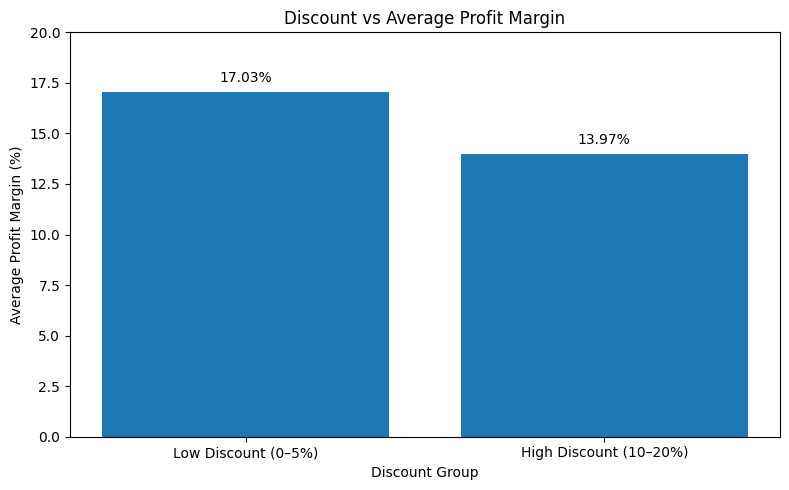

In [18]:
# Calculate average profit margins
margin_values = [
    low_discount.mean() * 100,
    high_discount.mean() * 100
]

labels = ["Low Discount (0–5%)", "High Discount (10–20%)"]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, margin_values)

plt.title("Discount vs Average Profit Margin")
plt.xlabel("Discount Group")
plt.ylabel("Average Profit Margin (%)")
plt.ylim(0, 20)

plt.bar_label(bars, fmt="%.2f%%", padding=5)

plt.tight_layout()
plt.show()

In [19]:
correlation, p_value_corr = stats.pearsonr(
    df["Discount"],
    df["Profit_Margin"]
)

print("Correlation:", round(correlation, 3))
print("P-Value:", p_value_corr)

if correlation < 0:
    print("Negative Relationship: Discount increases, profit margin tends to decrease.")
else:
    print("Positive Relationship: Discount increases, profit margin tends to increase.")

Correlation: -0.295
P-Value: 1.6804012139798462e-25
Negative Relationship: Discount increases, profit margin tends to decrease.


In [20]:
print("========== TASK 4: KEY FINDINGS ==========")

print("\n1. DATASET")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("\n2. BUSINESS PERFORMANCE")
print("Total Sales: ₹", round(df["Sales"].sum(), 2))
print("Total Profit: ₹", round(df["Profit"].sum(), 2))
print("Profit Margin:", round(profit_margin, 2), "%")

print("\n3. DISCOUNT ANALYSIS")
print("Low Discount Margin:", round(low_discount.mean()*100, 2), "%")
print("High Discount Margin:", round(high_discount.mean()*100, 2), "%")
print("Correlation:", round(correlation, 3))
print("Statistical Test P-Value:", p_value)

print("\n4. DATA QUALITY")
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\n========== ANALYSIS COMPLETED ==========")

========== TASK 4: KEY FINDINGS ==========

1. DATASET
Total Records: 1200
Total Columns: 16

2. BUSINESS PERFORMANCE
Total Sales: ₹ 71404219.75
Total Profit: ₹ 10715237.39
Profit Margin: 15.01 %

3. DISCOUNT ANALYSIS
Low Discount Margin: 17.03 %
High Discount Margin: 13.97 %
Correlation: -0.295
Statistical Test P-Value: 1.6639798800392473e-18

4. DATA QUALITY
Missing Values: 0
Duplicate Rows: 0

========== ANALYSIS COMPLETED ==========
